In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from joblib import load, dump
from time import time

In [9]:
df = pd.read_csv("dataset/droidware.csv")

In [10]:
df.head()

,Sha256,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,...,OnPauseCallCount,GetSimSerialNumberCallCount,Internet,AccessCoarseLocation,Vibrate,AccessFineLocation,SendSms,ChangeWifiState,Bluetooth,Label
0,117E78E2A1B4BB9FE9FFC6306DD5A3929B3C1C7570C5EA...,6,33,5,24,1401,21,276,0,745,...,16,0,1,1,1,1,0,0,0,0
1,76E174528B209FE8DDDDF14A81EE3FCDCD17714B1E7EE2...,0,1,0,0,2,0,1,1,0,...,0,0,1,1,1,1,1,1,0,1
2,09B0C75F48B158AE509AABFDAB5488CD23F6154CFA2B12...,2,49,7,35,3940,73,332,0,646,...,10,0,1,0,0,0,0,0,0,0
3,78274ACE743BD9482997FDCD9D04C1921F557F5D2179F9...,108,39,2,0,5061,56,486,0,575,...,75,1,1,0,0,1,0,1,0,1
4,7D68E4D1E2C7FD4AB554B7FF5A05FDD6405E54A0D2702B...,206,60,8,74,6712,61,637,0,604,...,66,0,1,0,0,0,0,1,1,1


In [11]:
df.shape

(265423, 70)

In [12]:
df.columns

Index(['Sha256', 'IPCAbuse', 'NDK', 'ServiceLifecycle', 'WorkManager',
       'TotalJavaFile', 'JavaLangReflectMethod', 'RootAccess', 'ReadSms',
       'ContentResolver', 'UseFingerprint', 'JavaSecurityCertX509Certificate',
       'ReceiveSms', 'CustomPermission', 'BluetoothAdmin', 'JavaNetSocket',
       'UpdateAppOpsStats', 'IntentSniffing', 'JavaNetUrl', 'UseBiometric',
       'AccessNetworkState', 'AccountManager', 'WebViewExploits',
       'ReadUserDictionary', 'ContentProvider', 'Vibrate1', 'ChangeWifiState1',
       'JavaxNetSslSslsocket', 'JavaSecurityCertCertificateFactory',
       'JavaNioFileAttributeFileTime', 'JavaNetHttpURLConnection',
       'JavaNetUri', 'JavaSecurityKeyPair', 'JavaNioFileStandardCopyOption',
       'JavaSecurityKeyFactory', 'JavaNetInetAddress',
       'JavaNioFileAttributeUserPrincipal', 'CheckSelfPermissionCallCount',
       'GetConnectionInfoCallCount', 'GetSubscriberIdCallCount',
       'GetDeviceIdCallCount', 'GetDrawableOccurrences', 'OnResumeOcc

In [13]:
df.duplicated().sum()

np.int64(0)

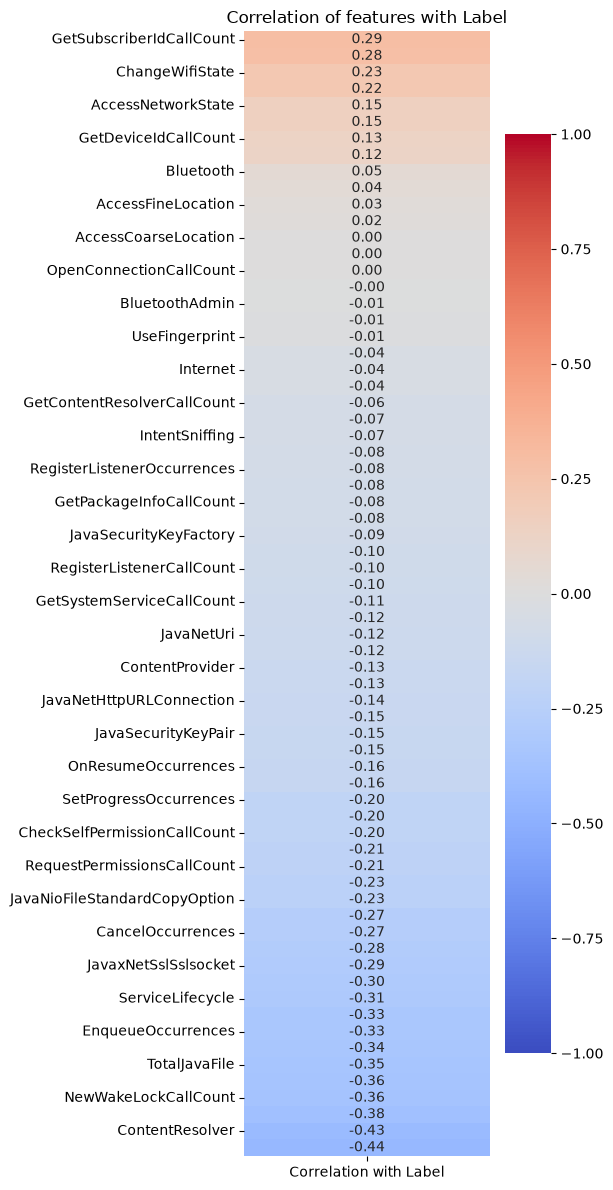

In [14]:
corr = df.corr(numeric_only=True)["Label"].drop("Label")
corr = corr.sort_values(ascending=False)

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr.to_frame(name="Correlation with Label"),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation of features with Label")
plt.tight_layout()
plt.show()

# Partition the table into subtables and study each

In [15]:
df1 = df.iloc[:, :11]
df1.head()

,Sha256,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,UseFingerprint
0,117E78E2A1B4BB9FE9FFC6306DD5A3929B3C1C7570C5EA...,6,33,5,24,1401,21,276,0,745,0
1,76E174528B209FE8DDDDF14A81EE3FCDCD17714B1E7EE2...,0,1,0,0,2,0,1,1,0,0
2,09B0C75F48B158AE509AABFDAB5488CD23F6154CFA2B12...,2,49,7,35,3940,73,332,0,646,0
3,78274ACE743BD9482997FDCD9D04C1921F557F5D2179F9...,108,39,2,0,5061,56,486,0,575,0
4,7D68E4D1E2C7FD4AB554B7FF5A05FDD6405E54A0D2702B...,206,60,8,74,6712,61,637,0,604,0


In [16]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 265423 entries, 0 to 265422
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype
---  ------                 --------------   -----
 0   Sha256                 265423 non-null  str  
 1   IPCAbuse               265423 non-null  int64
 2   NDK                    265423 non-null  int64
 3   ServiceLifecycle       265423 non-null  int64
 4   WorkManager            265423 non-null  int64
 5   TotalJavaFile          265423 non-null  int64
 6   JavaLangReflectMethod  265423 non-null  int64
 7   RootAccess             265423 non-null  int64
 8   ReadSms                265423 non-null  int64
 9   ContentResolver        265423 non-null  int64
 10  UseFingerprint         265423 non-null  int64
dtypes: int64(10), str(1)
memory usage: 22.3 MB


In [17]:
df1.describe()

,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,UseFingerprint
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,147.139268,38.667791,2.327824,22.589214,3099.137795,40.164447,230.185828,0.101841,306.352121,0.088003
std,909.606947,56.962629,4.399185,152.688652,3734.206593,44.332596,236.307748,0.331126,335.095197,1.442182
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,22.000000,2.000000,1.000000,0.000000,0.000000,0.000000
50%,13.000000,23.000000,0.000000,7.000000,1967.000000,33.000000,189.000000,0.000000,167.000000,0.000000
75%,43.000000,57.000000,4.000000,34.000000,4880.000000,61.000000,374.000000,0.000000,632.000000,0.000000
max,50409.000000,3874.000000,317.000000,27163.000000,53952.000000,2412.000000,4668.000000,9.000000,9202.000000,213.000000


In [18]:
df["AccountManager"].head()

0     80
1      0
2    127
3    277
4    703
Name: AccountManager, dtype: int64

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 265423 entries, 0 to 265422
Data columns (total 70 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Sha256                              265423 non-null  str  
 1   IPCAbuse                            265423 non-null  int64
 2   NDK                                 265423 non-null  int64
 3   ServiceLifecycle                    265423 non-null  int64
 4   WorkManager                         265423 non-null  int64
 5   TotalJavaFile                       265423 non-null  int64
 6   JavaLangReflectMethod               265423 non-null  int64
 7   RootAccess                          265423 non-null  int64
 8   ReadSms                             265423 non-null  int64
 9   ContentResolver                     265423 non-null  int64
 10  UseFingerprint                      265423 non-null  int64
 11  JavaSecurityCertX509Certificate     265423 non-null  int64
 12 

In [20]:
df1.describe()

,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,UseFingerprint
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,147.139268,38.667791,2.327824,22.589214,3099.137795,40.164447,230.185828,0.101841,306.352121,0.088003
std,909.606947,56.962629,4.399185,152.688652,3734.206593,44.332596,236.307748,0.331126,335.095197,1.442182
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,22.000000,2.000000,1.000000,0.000000,0.000000,0.000000
50%,13.000000,23.000000,0.000000,7.000000,1967.000000,33.000000,189.000000,0.000000,167.000000,0.000000
75%,43.000000,57.000000,4.000000,34.000000,4880.000000,61.000000,374.000000,0.000000,632.000000,0.000000
max,50409.000000,3874.000000,317.000000,27163.000000,53952.000000,2412.000000,4668.000000,9.000000,9202.000000,213.000000


In [21]:
df1.isnull().sum()

Sha256                   0
IPCAbuse                 0
NDK                      0
ServiceLifecycle         0
WorkManager              0
TotalJavaFile            0
JavaLangReflectMethod    0
RootAccess               0
ReadSms                  0
ContentResolver          0
UseFingerprint           0
dtype: int64

In [22]:
df1.duplicated().sum()

np.int64(0)

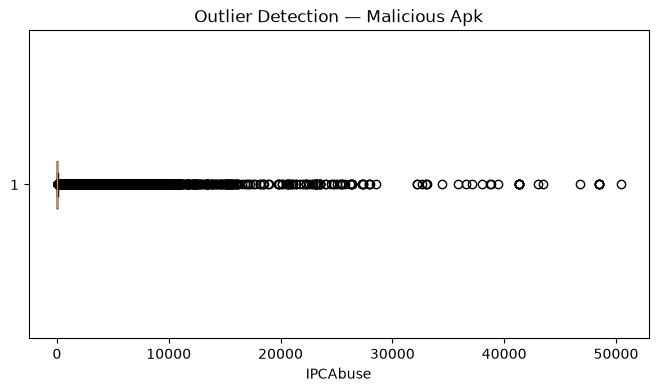

In [23]:
plt.figure(figsize=(8, 4))
plt.boxplot(df1["IPCAbuse"], orientation="horizontal")

plt.xlabel("IPCAbuse")
plt.title("Outlier Detection — Malicious Apk")
plt.show()

In [24]:
def show_limits(df):
    for col in df.select_dtypes(include="number").columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        lower = (q1 - 1.5 * iqr).round(2)
        upper = (q3 + 1.5 * iqr).round(2)

        outliers = df[col][
            (df[col] < lower) | (df[col] > upper)
        ]

        percentage = len(outliers) / df[col].notna().sum() * 100
        print(f"{col}: {percentage:.2f}% outliers")
        print(lower, upper)

show_limits(df1)

IPCAbuse: 14.30% outliers
-64.5 107.5
NDK: 4.01% outliers
-85.5 142.5
ServiceLifecycle: 2.27% outliers
-6.0 10.0
WorkManager: 5.40% outliers
-51.0 85.0
TotalJavaFile: 2.78% outliers
-7265.0 12167.0
JavaLangReflectMethod: 2.52% outliers
-86.5 149.5
RootAccess: 1.36% outliers
-558.5 933.5
ReadSms: 9.57% outliers
0.0 0.0
ContentResolver: 0.13% outliers
-948.0 1580.0
UseFingerprint: 5.28% outliers
0.0 0.0


In [25]:
def transform_outliers(df):
    for col in df.select_dtypes(include="number").columns:
        df[col] = np.log1p(df[col])

transform_outliers(df1)

In [26]:
show_limits(df1)

IPCAbuse: 0.06% outliers
-5.68 9.46
NDK: 0.00% outliers
-6.09 10.15
ServiceLifecycle: 0.07% outliers
-2.41 4.02
WorkManager: 0.00% outliers
-5.33 8.89
TotalJavaFile: 0.00% outliers
-4.9 16.53
JavaLangReflectMethod: 0.00% outliers
-3.44 8.67
RootAccess: 0.00% outliers
-7.16 13.78
ReadSms: 9.57% outliers
0.0 0.0
ContentResolver: 0.00% outliers
-9.68 16.13
UseFingerprint: 5.28% outliers
0.0 0.0


In [27]:
df1.describe()

,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,UseFingerprint
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,2.507571,2.478936,0.717849,1.813602,6.195489,2.841215,3.996312,0.068543,3.851620,0.042379
std,2.039440,1.892550,0.918393,1.797117,2.960002,1.613501,2.469552,0.213708,2.829099,0.198388
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,3.135494,1.098612,0.693147,0.000000,0.000000,0.000000
50%,2.639057,3.178054,0.000000,2.079442,7.584773,3.526361,5.247024,0.000000,5.123964,0.000000
75%,3.784190,4.060443,1.609438,3.555348,8.493105,4.127134,5.926926,0.000000,6.450470,0.000000
max,10.827945,8.262301,5.762051,10.209648,10.895869,7.788626,8.448700,2.302585,9.127285,5.365976


In [28]:
df1.corr(numeric_only=True)

,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,UseFingerprint
IPCAbuse,1.000000,0.388440,0.362750,0.476610,0.468475,0.466503,0.462438,0.126330,0.422954,0.268633
NDK,0.388440,1.000000,0.616987,0.679621,0.884328,0.900694,0.901146,-0.175482,0.876221,-0.048320
ServiceLifecycle,0.362750,0.616987,1.000000,0.748638,0.582196,0.624898,0.568193,-0.175574,0.583547,0.122651
WorkManager,0.476610,0.679621,0.748638,1.000000,0.588615,0.687779,0.577232,-0.120977,0.617743,0.188077
TotalJavaFile,0.468475,0.884328,0.582196,0.588615,1.000000,0.929778,0.969456,-0.193443,0.876419,-0.043637
JavaLangReflectMethod,0.466503,0.900694,0.624898,0.687779,0.929778,1.000000,0.906508,-0.171126,0.886713,0.048015
RootAccess,0.462438,0.901146,0.568193,0.577232,0.969456,0.906508,1.000000,-0.194974,0.894185,-0.093485
ReadSms,0.126330,-0.175482,-0.175574,-0.120977,-0.193443,-0.171126,-0.194974,1.000000,-0.172955,0.155106
ContentResolver,0.422954,0.876221,0.583547,0.617743,0.876419,0.886713,0.894185,-0.172955,1.000000,-0.013613
UseFingerprint,0.268633,-0.048320,0.122651,0.188077,-0.043637,0.048015,-0.093485,0.155106,-0.013613,1.000000


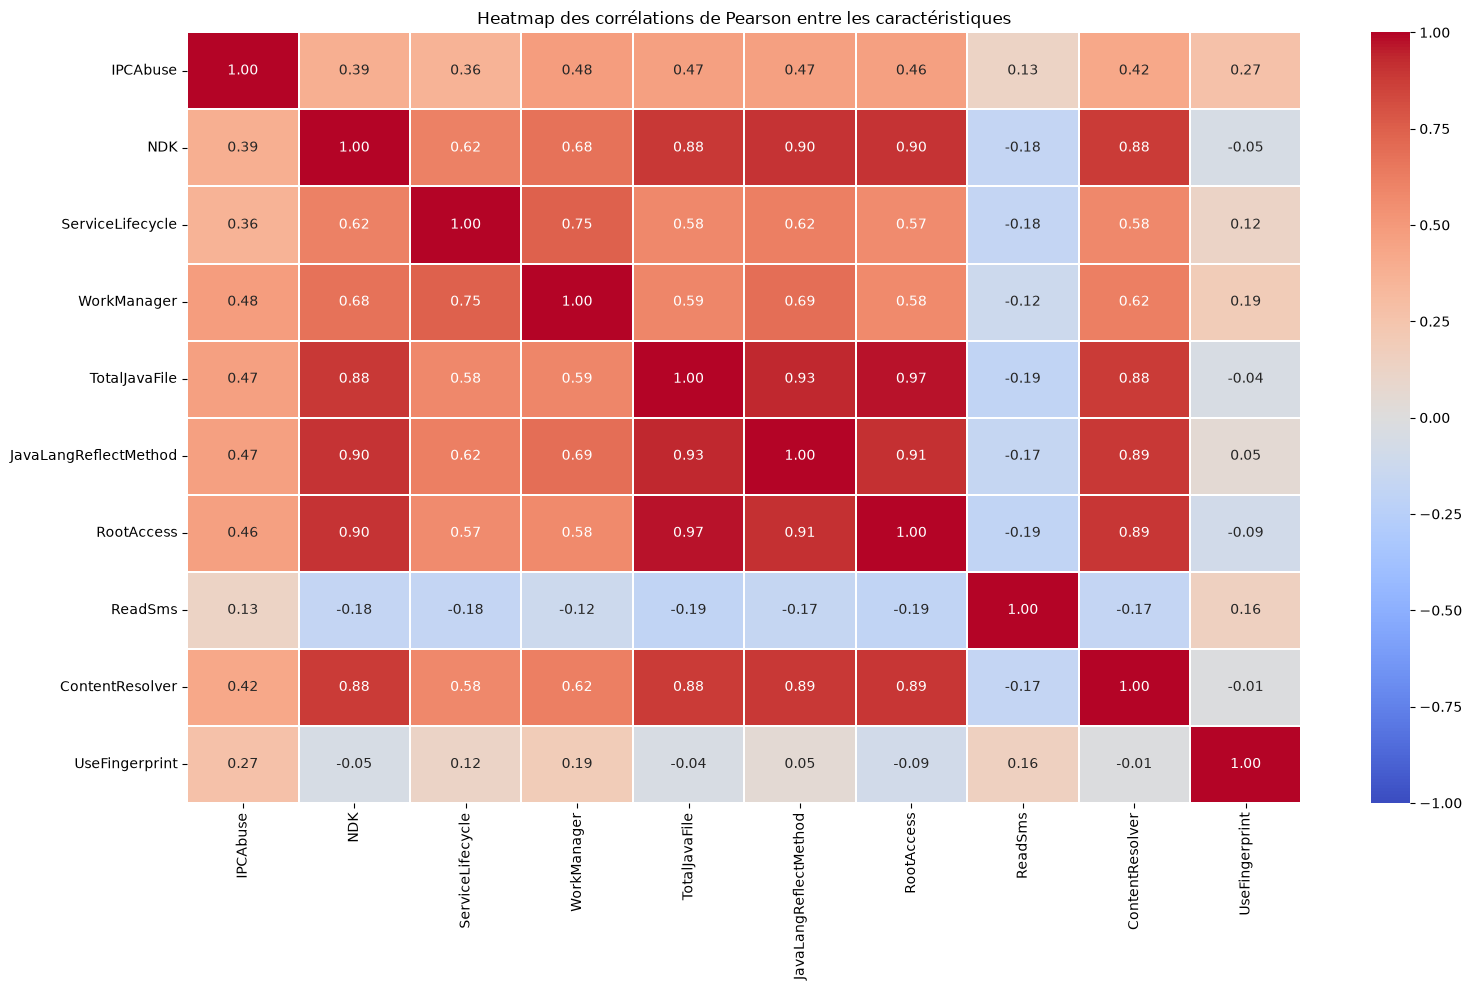

In [29]:
corr = df1.corr(method="pearson",
                numeric_only=True)

plt.figure(figsize=(16, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3
)

plt.title("Heatmap des corrélations de Pearson entre les caractéristiques")
plt.tight_layout()
plt.show()

array([[<Axes: title={'center': 'IPCAbuse'}>,
        <Axes: title={'center': 'NDK'}>,
        <Axes: title={'center': 'ServiceLifecycle'}>],
       [<Axes: title={'center': 'WorkManager'}>,
        <Axes: title={'center': 'TotalJavaFile'}>,
        <Axes: title={'center': 'JavaLangReflectMethod'}>],
       [<Axes: title={'center': 'RootAccess'}>,
        <Axes: title={'center': 'ReadSms'}>,
        <Axes: title={'center': 'ContentResolver'}>],
       [<Axes: title={'center': 'UseFingerprint'}>, <Axes: >, <Axes: >]],
      dtype=object)

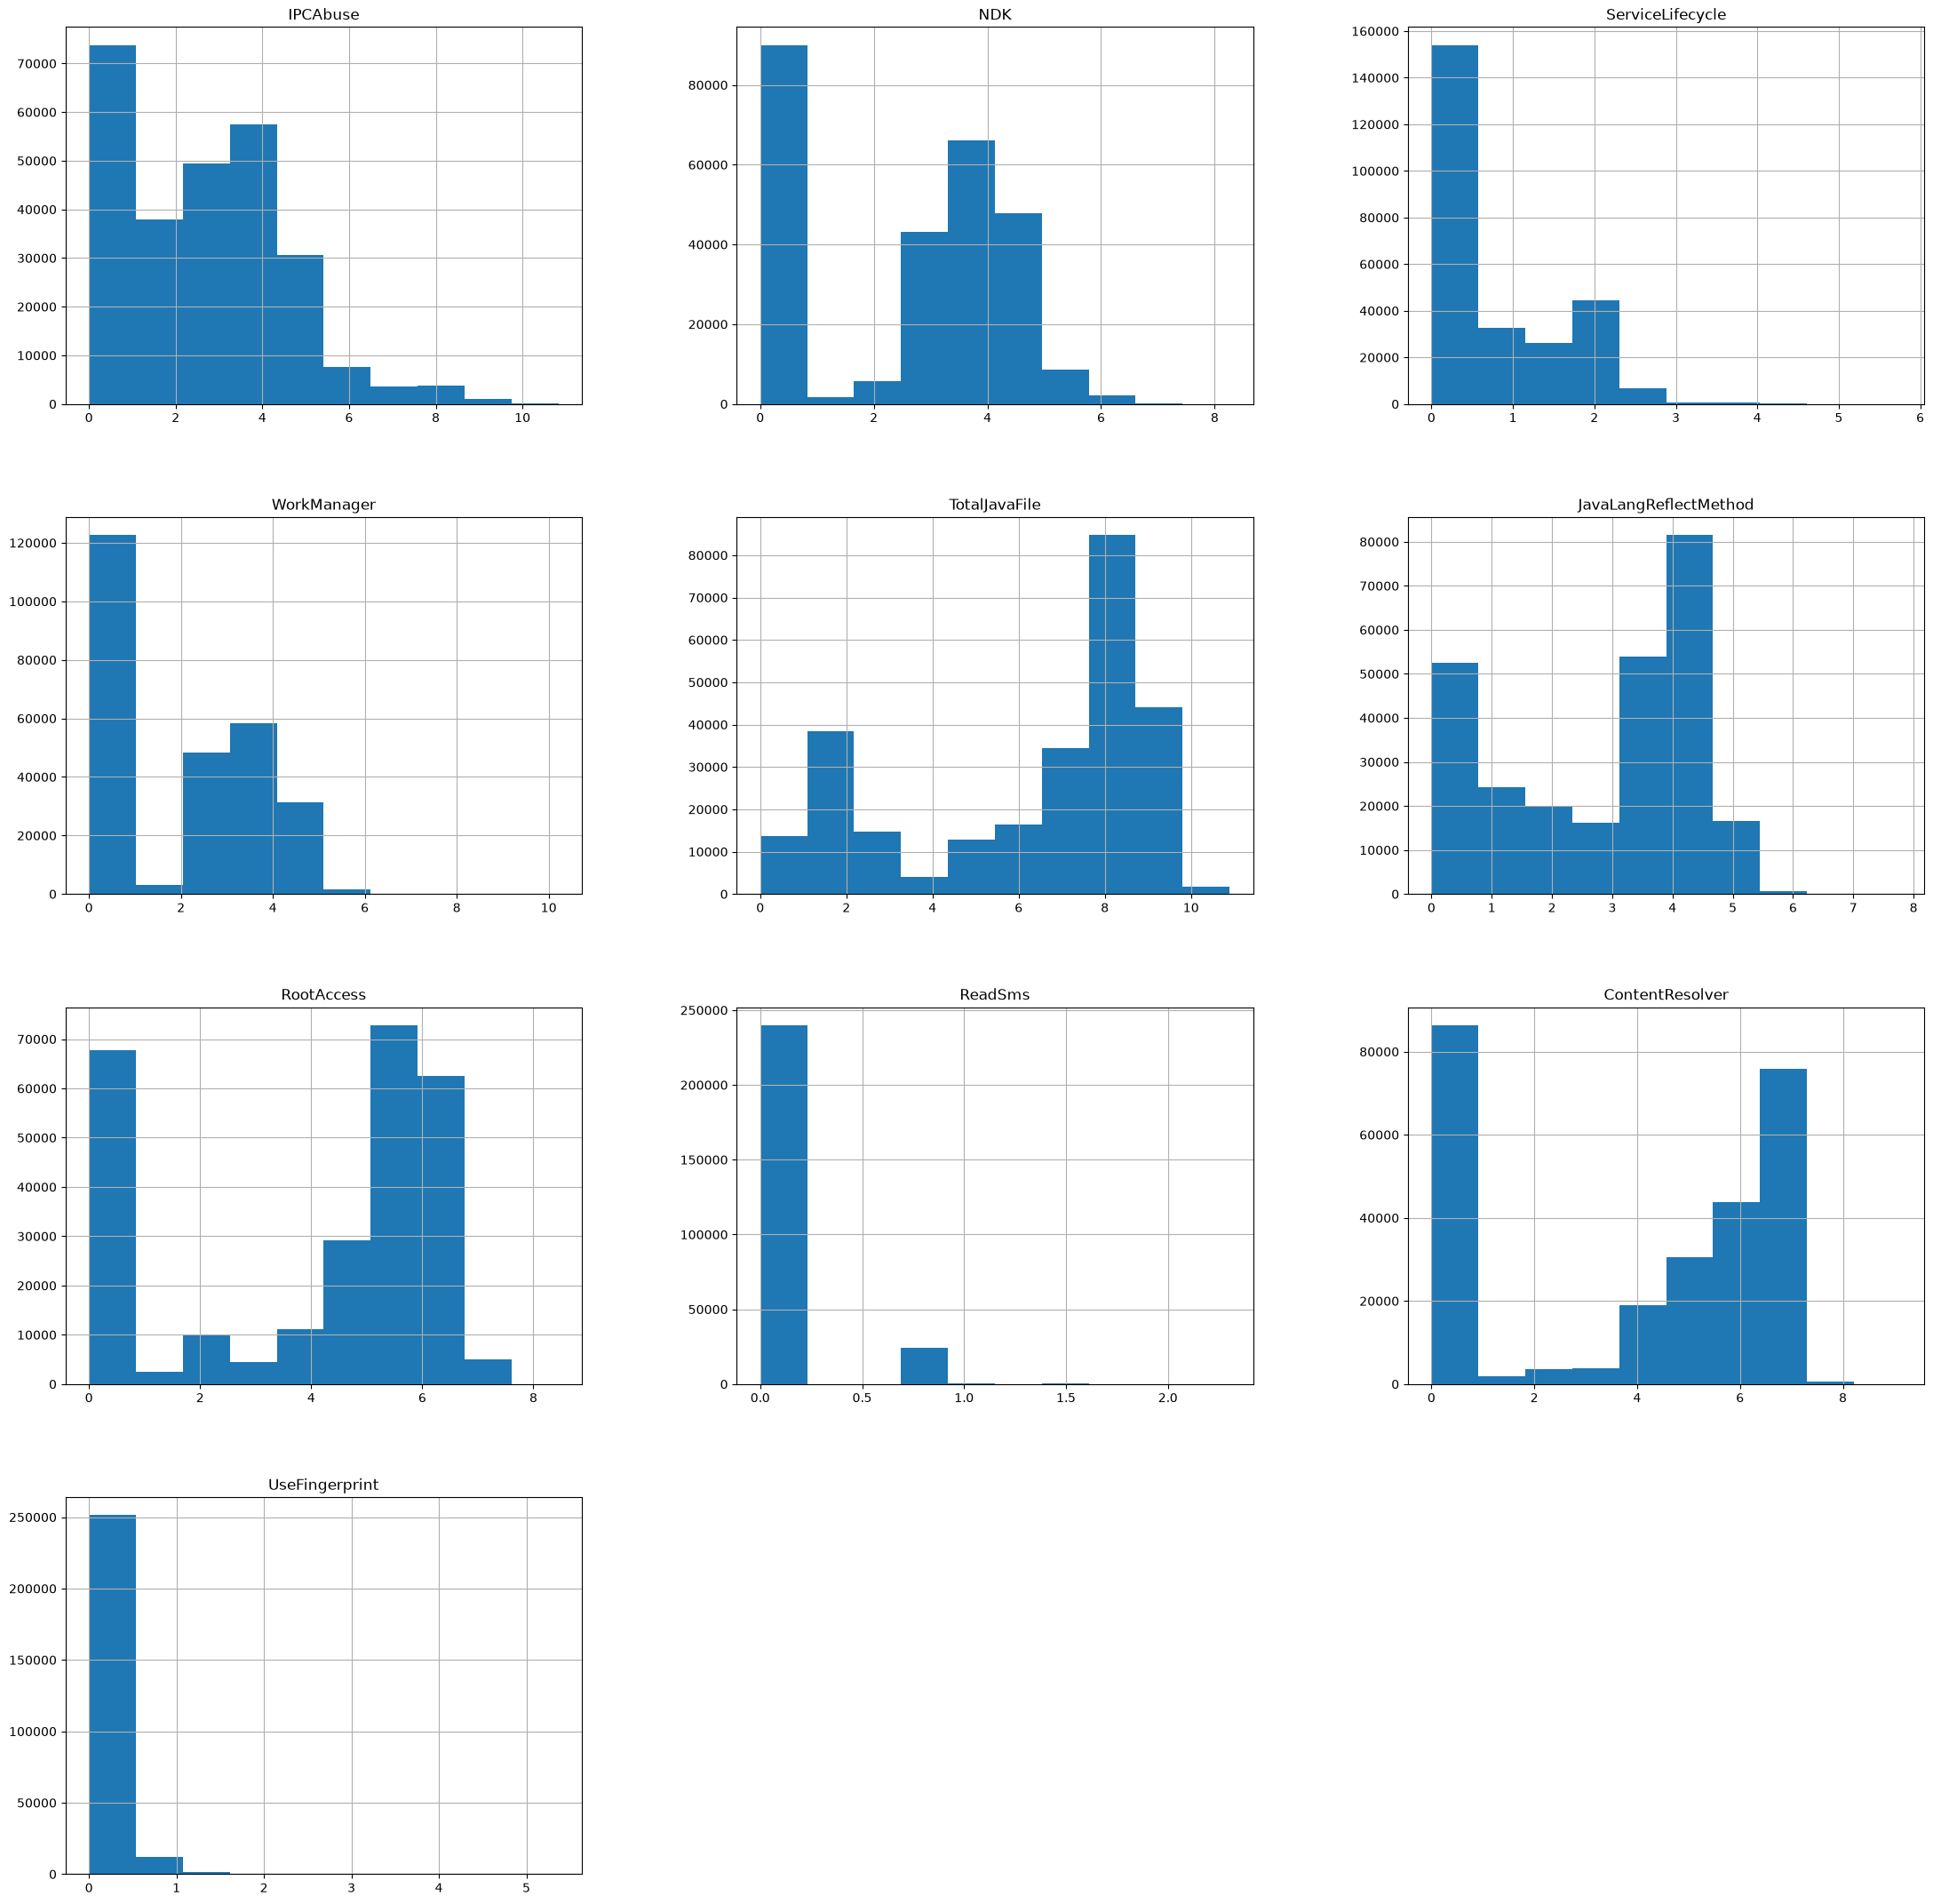

In [30]:
df1.hist(figsize=(27, 27))

# Treat second part

In [31]:
df2 = df.iloc[:, 11:21]

In [32]:
df2.head()

,JavaSecurityCertX509Certificate,ReceiveSms,CustomPermission,BluetoothAdmin,JavaNetSocket,UpdateAppOpsStats,IntentSniffing,JavaNetUrl,UseBiometric,AccessNetworkState
0,2,0,107,0,21,0,12,11,0,1
1,0,1,0,0,0,1,0,0,0,1
2,24,0,121,0,141,0,26,38,0,1
3,9,0,221,0,26,0,99,66,0,1
4,15,0,476,1,10,0,55,82,0,1


In [33]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 265423 entries, 0 to 265422
Data columns (total 10 columns):
 #   Column                           Non-Null Count   Dtype
---  ------                           --------------   -----
 0   JavaSecurityCertX509Certificate  265423 non-null  int64
 1   ReceiveSms                       265423 non-null  int64
 2   CustomPermission                 265423 non-null  int64
 3   BluetoothAdmin                   265423 non-null  int64
 4   JavaNetSocket                    265423 non-null  int64
 5   UpdateAppOpsStats                265423 non-null  int64
 6   IntentSniffing                   265423 non-null  int64
 7   JavaNetUrl                       265423 non-null  int64
 8   UseBiometric                     265423 non-null  int64
 9   AccessNetworkState               265423 non-null  int64
dtypes: int64(10)
memory usage: 20.3 MB


In [34]:
df2.describe()

,JavaSecurityCertX509Certificate,ReceiveSms,CustomPermission,BluetoothAdmin,JavaNetSocket,UpdateAppOpsStats,IntentSniffing,JavaNetUrl,UseBiometric,AccessNetworkState
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,8.295427,0.133677,94.605211,0.339191,26.223545,0.057911,36.836427,30.309227,0.098085,0.851806
std,16.960257,1.935431,116.563057,3.068660,33.486184,0.562968,50.970103,46.211980,3.389760,0.355292
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,1.000000,0.000000,61.000000,0.000000,16.000000,0.000000,24.000000,14.000000,0.000000,1.000000
75%,11.000000,0.000000,138.000000,0.000000,43.000000,0.000000,52.000000,37.000000,0.000000,1.000000
max,379.000000,299.000000,2396.000000,216.000000,1443.000000,58.000000,3198.000000,1093.000000,661.000000,1.000000


In [35]:
df2["AccessNetworkState"].unique()

array([1, 0])

In [36]:
show_limits(df2)

JavaSecurityCertX509Certificate: 6.97% outliers
-16.5 27.5
ReceiveSms: 8.91% outliers
0.0 0.0
CustomPermission: 4.89% outliers
-194.5 337.5
BluetoothAdmin: 11.93% outliers
0.0 0.0
JavaNetSocket: 2.55% outliers
-64.5 107.5
UpdateAppOpsStats: 3.30% outliers
0.0 0.0
IntentSniffing: 4.26% outliers
-78.0 130.0
JavaNetUrl: 9.16% outliers
-55.5 92.5
UseBiometric: 3.01% outliers
0.0 0.0
AccessNetworkState: 14.82% outliers
1.0 1.0


In [37]:
transform_outliers(df2)

In [38]:
show_limits(df2)

JavaSecurityCertX509Certificate: 0.00% outliers
-3.73 6.21
ReceiveSms: 8.91% outliers
0.0 0.0
CustomPermission: 0.00% outliers
-2.92 9.65
BluetoothAdmin: 11.93% outliers
0.0 0.0
JavaNetSocket: 0.00% outliers
-5.68 9.46
UpdateAppOpsStats: 3.30% outliers
0.0 0.0
IntentSniffing: 0.00% outliers
-5.96 9.93
JavaNetUrl: 0.00% outliers
-5.46 9.09
UseBiometric: 3.01% outliers
0.0 0.0
AccessNetworkState: 100.00% outliers
0.69 0.69


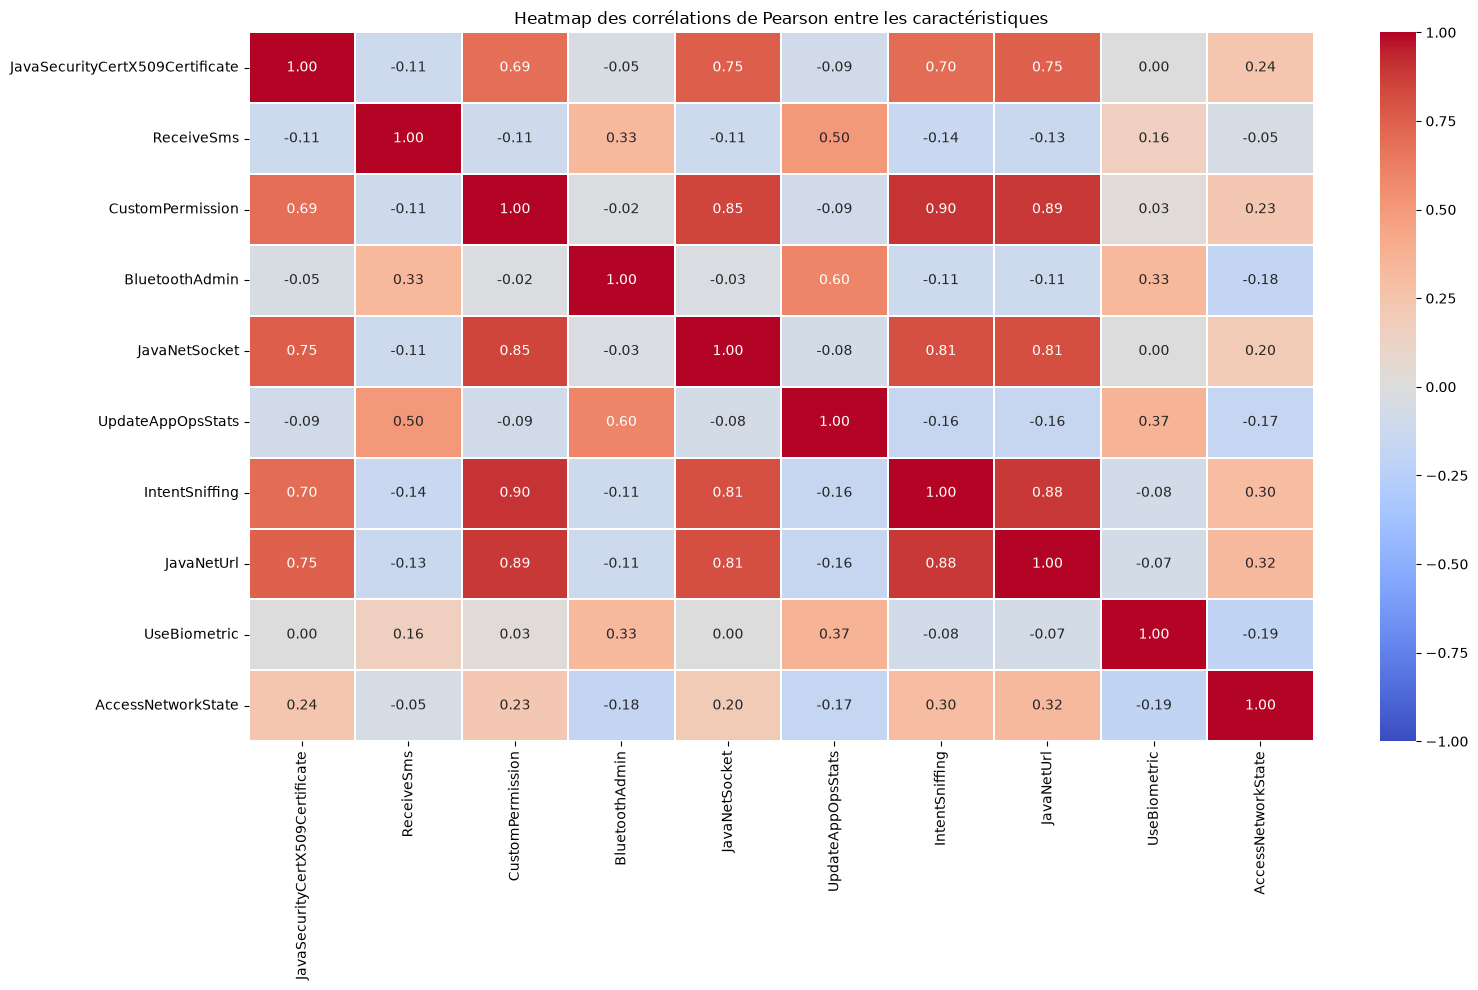

In [39]:
corr = df2.corr(method="pearson",
                numeric_only=True)

plt.figure(figsize=(16, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3
)

plt.title("Heatmap des corrélations de Pearson entre les caractéristiques")
plt.tight_layout()
plt.show()

## Treat third part

In [40]:
df3 = df.iloc[:, 21:31]

In [41]:
df3.head()

,AccountManager,WebViewExploits,ReadUserDictionary,ContentProvider,Vibrate1,ChangeWifiState1,JavaxNetSslSslsocket,JavaSecurityCertCertificateFactory,JavaNioFileAttributeFileTime,JavaNetHttpURLConnection
0,80,60,0,0,1,0,0,0,0,6
1,0,0,1,0,1,1,0,0,0,0
2,127,93,0,0,0,0,63,4,0,13
3,277,147,0,13,0,1,13,2,0,27
4,703,84,0,55,0,1,12,1,0,44


In [42]:
df3.describe()

,AccountManager,WebViewExploits,ReadUserDictionary,ContentProvider,Vibrate1,ChangeWifiState1,JavaxNetSslSslsocket,JavaSecurityCertCertificateFactory,JavaNioFileAttributeFileTime,JavaNetHttpURLConnection
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,223.628608,82.472325,0.015021,26.723969,1.297393,2.291693,13.841359,1.609137,0.087573,14.771776
std,338.738045,108.143934,0.121638,104.650609,19.834806,13.996605,24.287000,3.271068,0.429482,21.387085
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,135.000000,57.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,6.000000
75%,310.000000,120.000000,0.000000,0.000000,1.000000,1.000000,23.000000,2.000000,0.000000,21.000000
max,52593.000000,2461.000000,1.000000,7489.000000,1111.000000,969.000000,1012.000000,72.000000,24.000000,470.000000


In [43]:
df["ReadUserDictionary"].unique()

array([0, 1])

In [44]:
show_limits(df3)

AccountManager: 4.81% outliers
-465.0 775.0
WebViewExploits: 3.49% outliers
-180.0 300.0
ReadUserDictionary: 1.50% outliers
0.0 0.0
ContentProvider: 21.37% outliers
0.0 0.0
Vibrate1: 0.75% outliers
-1.5 2.5
ChangeWifiState1: 3.80% outliers
-1.5 2.5
JavaxNetSslSslsocket: 3.87% outliers
-34.5 57.5
JavaSecurityCertCertificateFactory: 6.66% outliers
-3.0 5.0
JavaNioFileAttributeFileTime: 7.19% outliers
0.0 0.0
JavaNetHttpURLConnection: 6.47% outliers
-31.5 52.5


In [45]:
transform_outliers(df3)

In [46]:
show_limits(df3)

AccountManager: 0.00% outliers
-8.61 14.35
WebViewExploits: 0.00% outliers
-7.19 11.99
ReadUserDictionary: 1.50% outliers
0.0 0.0
ContentProvider: 21.37% outliers
0.0 0.0
Vibrate1: 0.75% outliers
-1.04 1.73
ChangeWifiState1: 3.77% outliers
-1.04 1.73
JavaxNetSslSslsocket: 0.00% outliers
-4.77 7.95
JavaSecurityCertCertificateFactory: 1.01% outliers
-1.65 2.75
JavaNioFileAttributeFileTime: 7.19% outliers
0.0 0.0
JavaNetHttpURLConnection: 0.00% outliers
-4.64 7.73


In [47]:
df3[["ChangeWifiState1", "JavaSecurityCertCertificateFactory"]].describe()

,ChangeWifiState1,JavaSecurityCertCertificateFactory
count,265423.000000,265423.000000
mean,0.334565,0.608174
std,0.751844,0.741583
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.693147,1.098612
max,6.877296,4.290459


# Treat Fourth Part 

In [48]:
df4 = df.iloc[:, 31:41]

In [49]:
df4.head()

,JavaNetUri,JavaSecurityKeyPair,JavaNioFileStandardCopyOption,JavaSecurityKeyFactory,JavaNetInetAddress,JavaNioFileAttributeUserPrincipal,CheckSelfPermissionCallCount,GetConnectionInfoCallCount,GetSubscriberIdCallCount,GetDeviceIdCallCount
0,1,5,0,1,1,0,8,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,53,5,0,2,58,0,6,0,0,3
3,40,5,0,5,7,0,7,4,0,7
4,28,6,0,5,4,0,16,3,1,6


In [50]:
df4.describe()

,JavaNetUri,JavaSecurityKeyPair,JavaNioFileStandardCopyOption,JavaSecurityKeyFactory,JavaNetInetAddress,JavaNioFileAttributeUserPrincipal,CheckSelfPermissionCallCount,GetConnectionInfoCallCount,GetSubscriberIdCallCount,GetDeviceIdCallCount
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,8.819481,3.499312,0.127163,2.405447,6.731029,0.056962,4.752919,2.041164,1.073682,5.098047
std,14.550861,13.097388,0.450485,9.282909,10.851804,0.303470,10.725917,5.610220,3.565313,9.568964
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,0.000000,0.000000,1.000000,2.000000,0.000000,1.000000,0.000000,0.000000,3.000000
75%,11.000000,5.000000,0.000000,3.000000,10.000000,0.000000,6.000000,1.000000,0.000000,5.000000
max,555.000000,414.000000,12.000000,276.000000,167.000000,23.000000,2658.000000,110.000000,155.000000,353.000000


In [51]:
show_limits(df4)

JavaNetUri: 10.44% outliers
-16.5 27.5
JavaSecurityKeyPair: 3.64% outliers
-7.5 12.5
JavaNioFileStandardCopyOption: 9.36% outliers
0.0 0.0
JavaSecurityKeyFactory: 3.43% outliers
-4.5 7.5
JavaNetInetAddress: 6.49% outliers
-15.0 25.0
JavaNioFileAttributeUserPrincipal: 5.36% outliers
0.0 0.0
CheckSelfPermissionCallCount: 8.24% outliers
-9.0 15.0
GetConnectionInfoCallCount: 16.39% outliers
-1.5 2.5
GetSubscriberIdCallCount: 20.04% outliers
0.0 0.0
GetDeviceIdCallCount: 9.21% outliers
-7.5 12.5


In [52]:
transform_outliers(df4)

In [53]:
show_limits(df4)

JavaNetUri: 0.00% outliers
-3.73 6.21
JavaSecurityKeyPair: 0.56% outliers
-2.69 4.48
JavaNioFileStandardCopyOption: 9.36% outliers
0.0 0.0
JavaSecurityKeyFactory: 0.90% outliers
-2.08 3.47
JavaNetInetAddress: 0.00% outliers
-3.6 5.99
JavaNioFileAttributeUserPrincipal: 5.36% outliers
0.0 0.0
CheckSelfPermissionCallCount: 0.05% outliers
-2.92 4.86
GetConnectionInfoCallCount: 10.85% outliers
-1.04 1.73
GetSubscriberIdCallCount: 20.04% outliers
0.0 0.0
GetDeviceIdCallCount: 0.10% outliers
-2.69 4.48


In [54]:
df4.describe()

,JavaNetUri,JavaSecurityKeyPair,JavaNioFileStandardCopyOption,JavaSecurityKeyFactory,JavaNetInetAddress,JavaNioFileAttributeUserPrincipal,CheckSelfPermissionCallCount,GetConnectionInfoCallCount,GetSubscriberIdCallCount,GetDeviceIdCallCount
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,1.413703,0.730766,0.077319,0.717955,1.279551,0.037909,1.082422,0.510728,0.301743,1.236707
std,1.334439,1.039034,0.251157,0.791714,1.225311,0.162180,1.104442,0.872275,0.697206,1.008160
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.386294,0.000000,0.000000,0.693147,1.098612,0.000000,0.693147,0.000000,0.000000,1.386294
75%,2.484907,1.791759,0.000000,1.386294,2.397895,0.000000,1.945910,0.693147,0.000000,1.791759
max,6.320768,6.028279,2.564949,5.624018,5.123964,3.178054,7.885705,4.709530,5.049856,5.869297


## Treat a fifth section 

In [55]:
df5 = df.iloc[:, 41:51]

In [56]:
df5.head()

,GetDrawableOccurrences,OnResumeOccurrences,ConnectOccurrences,OnTouchCallCount,NewWakeLockCallCount,SetProgressOccurrences,GetPackageInfoCallCount,RemoveOccurrences,EnqueueOccurrences,GetSystemServiceCallCount
0,9,19,31,1,7,2,21,41,13,54
1,0,0,0,0,0,0,0,1,0,0
2,31,14,57,4,5,3,23,355,21,86
3,35,82,31,3,3,11,39,114,6,197
4,35,95,20,5,6,11,63,131,5,235


In [57]:
df5.describe()

,GetDrawableOccurrences,OnResumeOccurrences,ConnectOccurrences,OnTouchCallCount,NewWakeLockCallCount,SetProgressOccurrences,GetPackageInfoCallCount,RemoveOccurrences,EnqueueOccurrences,GetSystemServiceCallCount
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,14.302144,25.125121,13.113005,6.029647,2.957675,4.393877,20.489743,93.983656,4.350497,89.302826
std,14.216598,29.516964,16.899038,22.205670,3.342842,6.001381,26.074984,119.216477,7.067681,94.080619
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000,3.000000
50%,12.000000,15.000000,5.000000,3.000000,2.000000,3.000000,14.000000,61.000000,1.000000,74.000000
75%,26.000000,40.000000,22.000000,5.000000,5.000000,6.000000,31.000000,132.000000,5.000000,129.000000
max,137.000000,1115.000000,688.000000,898.000000,292.000000,74.000000,2362.000000,2319.000000,199.000000,2790.000000


In [58]:
show_limits(df5)

GetDrawableOccurrences: 0.05% outliers
-39.0 65.0
OnResumeOccurrences: 2.67% outliers
-60.0 100.0
ConnectOccurrences: 2.22% outliers
-33.0 55.0
OnTouchCallCount: 4.48% outliers
-7.5 12.5
NewWakeLockCallCount: 1.25% outliers
-7.5 12.5
SetProgressOccurrences: 6.27% outliers
-9.0 15.0
GetPackageInfoCallCount: 3.13% outliers
-46.5 77.5
RemoveOccurrences: 4.45% outliers
-188.0 324.0
EnqueueOccurrences: 15.14% outliers
-7.5 12.5
GetSystemServiceCallCount: 3.44% outliers
-186.0 318.0


In [59]:
transform_outliers(df5)

In [60]:
show_limits(df5)

GetDrawableOccurrences: 0.00% outliers
-4.94 8.24
OnResumeOccurrences: 0.00% outliers
-5.57 9.28
ConnectOccurrences: 0.00% outliers
-4.7 7.84
OnTouchCallCount: 1.38% outliers
-2.69 4.48
NewWakeLockCallCount: 0.00% outliers
-2.69 4.48
SetProgressOccurrences: 0.00% outliers
-2.92 4.86
GetPackageInfoCallCount: 0.00% outliers
-5.2 8.66
RemoveOccurrences: 0.00% outliers
-3.31 9.81
EnqueueOccurrences: 0.02% outliers
-2.69 4.48
GetSystemServiceCallCount: 0.00% outliers
-3.84 10.09


## Treat last part

In [61]:
df6 = df.iloc[:, 51:69]

In [62]:
df6.head()

,CancelOccurrences,SetAccessibleCallCount,OpenConnectionCallCount,RegisterListenerCallCount,GetContentResolverCallCount,RegisterListenerOccurrences,RequestPermissionsCallCount,GetPrimaryClipCallCount,GetPrimaryClipOccurrences,OnPauseCallCount,GetSimSerialNumberCallCount,Internet,AccessCoarseLocation,Vibrate,AccessFineLocation,SendSms,ChangeWifiState,Bluetooth
0,55,37,7,4,30,8,14,0,0,16,0,1,1,1,1,0,0,0
1,0,2,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,0
2,105,93,10,3,32,6,4,0,0,10,0,1,0,0,0,0,0,0
3,108,77,22,3,50,3,9,0,0,75,1,1,0,0,1,0,1,0
4,94,112,42,5,47,9,13,0,0,66,0,1,0,0,0,0,1,1


In [63]:
df6.describe()

,CancelOccurrences,SetAccessibleCallCount,OpenConnectionCallCount,RegisterListenerCallCount,GetContentResolverCallCount,RegisterListenerOccurrences,RequestPermissionsCallCount,GetPrimaryClipCallCount,GetPrimaryClipOccurrences,OnPauseCallCount,GetSimSerialNumberCallCount,Internet,AccessCoarseLocation,Vibrate,AccessFineLocation,SendSms,ChangeWifiState,Bluetooth
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,48.296896,47.675379,12.310508,3.707863,31.340683,4.170226,4.501249,0.659713,0.242164,16.931600,0.450884,5.425931,4.098236,1.026640,0.736873,0.623759,0.402354,0.309472
std,72.356488,46.945729,19.486085,8.814636,42.931553,15.937655,9.635366,2.751282,0.492128,21.330531,1.876839,32.422366,221.341324,4.906101,3.381903,3.496968,0.861958,1.511249
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,3.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,29.000000,44.000000,7.000000,1.000000,24.000000,1.000000,2.000000,0.000000,0.000000,10.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,70.000000,77.000000,16.000000,4.000000,43.000000,4.000000,6.000000,1.000000,0.000000,25.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000
max,9280.000000,3104.000000,786.000000,720.000000,1299.000000,791.000000,2127.000000,133.000000,35.000000,1098.000000,54.000000,1447.000000,30429.000000,411.000000,196.000000,89.000000,44.000000,83.000000


In [64]:
show_limits(df6)

CancelOccurrences: 3.99% outliers
-102.5 173.5
SetAccessibleCallCount: 0.92% outliers
-108.0 188.0
OpenConnectionCallCount: 5.69% outliers
-24.0 40.0
RegisterListenerCallCount: 7.22% outliers
-6.0 10.0
GetContentResolverCallCount: 4.20% outliers
-62.0 106.0
RegisterListenerOccurrences: 5.76% outliers
-6.0 10.0
RequestPermissionsCallCount: 5.58% outliers
-9.0 15.0
GetPrimaryClipCallCount: 5.35% outliers
-1.5 2.5
GetPrimaryClipOccurrences: 23.56% outliers
0.0 0.0
OnPauseCallCount: 4.92% outliers
-35.0 61.0
GetSimSerialNumberCallCount: 13.34% outliers
0.0 0.0
Internet: 11.13% outliers
1.0 1.0
AccessCoarseLocation: 4.28% outliers
-1.5 2.5
Vibrate: 4.34% outliers
-1.5 2.5
AccessFineLocation: 2.94% outliers
-1.5 2.5
SendSms: 13.20% outliers
0.0 0.0
ChangeWifiState: 2.48% outliers
-1.5 2.5
Bluetooth: 18.67% outliers
0.0 0.0


In [65]:
transform_outliers(df6)

In [66]:
show_limits(df6)

CancelOccurrences: 0.00% outliers
-4.66 9.62
SetAccessibleCallCount: 0.00% outliers
-3.07 8.81
OpenConnectionCallCount: 0.00% outliers
-4.25 7.08
RegisterListenerCallCount: 0.34% outliers
-2.41 4.02
GetContentResolverCallCount: 0.00% outliers
-3.94 8.42
RegisterListenerOccurrences: 0.81% outliers
-2.41 4.02
RequestPermissionsCallCount: 0.05% outliers
-2.92 4.86
GetPrimaryClipCallCount: 1.87% outliers
-1.04 1.73
GetPrimaryClipOccurrences: 23.56% outliers
0.0 0.0
OnPauseCallCount: 0.00% outliers
-3.15 7.11
GetSimSerialNumberCallCount: 13.34% outliers
0.0 0.0
Internet: 100.00% outliers
0.69 0.69
AccessCoarseLocation: 4.24% outliers
-1.04 1.73
Vibrate: 3.32% outliers
-1.04 1.73
AccessFineLocation: 1.75% outliers
-1.04 1.73
SendSms: 13.20% outliers
0.0 0.0
ChangeWifiState: 0.60% outliers
-1.04 1.73
Bluetooth: 18.67% outliers
0.0 0.0


In [67]:
df6.info()

<class 'pandas.DataFrame'>
RangeIndex: 265423 entries, 0 to 265422
Data columns (total 18 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   CancelOccurrences            265423 non-null  float64
 1   SetAccessibleCallCount       265423 non-null  float64
 2   OpenConnectionCallCount      265423 non-null  float64
 3   RegisterListenerCallCount    265423 non-null  float64
 4   GetContentResolverCallCount  265423 non-null  float64
 5   RegisterListenerOccurrences  265423 non-null  float64
 6   RequestPermissionsCallCount  265423 non-null  float64
 7   GetPrimaryClipCallCount      265423 non-null  float64
 8   GetPrimaryClipOccurrences    265423 non-null  float64
 9   OnPauseCallCount             265423 non-null  float64
 10  GetSimSerialNumberCallCount  265423 non-null  float64
 11  Internet                     265423 non-null  float64
 12  AccessCoarseLocation         265423 non-null  float64
 13  Vibrate   

In [68]:
df6.describe()

,CancelOccurrences,SetAccessibleCallCount,OpenConnectionCallCount,RegisterListenerCallCount,GetContentResolverCallCount,RegisterListenerOccurrences,RequestPermissionsCallCount,GetPrimaryClipCallCount,GetPrimaryClipOccurrences,OnPauseCallCount,GetSimSerialNumberCallCount,Internet,AccessCoarseLocation,Vibrate,AccessFineLocation,SendSms,ChangeWifiState,Bluetooth
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,2.741955,3.004504,1.810135,1.011217,2.541603,0.990999,1.104248,0.264686,0.164989,2.083097,0.165554,0.809403,0.415680,0.394559,0.335743,0.158147,0.242858,0.152279
std,1.871707,1.658646,1.336367,0.938502,1.648036,0.954482,1.064336,0.522575,0.300159,1.441158,0.478720,0.783633,0.784461,0.556832,0.484971,0.516379,0.389347,0.363570
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.693147,1.386294,0.000000,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.693147,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.401197,3.806662,2.079442,0.693147,3.218876,0.693147,1.098612,0.000000,0.000000,2.397895,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,4.262680,4.356709,2.833213,1.609438,3.784190,1.609438,1.945910,0.693147,0.000000,3.258097,0.000000,0.693147,0.693147,0.693147,0.693147,0.000000,0.693147,0.000000
max,9.135725,8.040769,6.668228,6.580639,7.170120,6.674561,7.662938,4.897840,3.583519,7.002156,4.007333,7.277939,10.323184,6.021023,5.283204,4.499810,3.806662,4.430817


In [69]:
df = pd.concat([df1, df2, df3, df4, df5, df6, df["Label"]], axis=1)

In [70]:
df.columns

Index(['Sha256', 'IPCAbuse', 'NDK', 'ServiceLifecycle', 'WorkManager',
       'TotalJavaFile', 'JavaLangReflectMethod', 'RootAccess', 'ReadSms',
       'ContentResolver', 'UseFingerprint', 'JavaSecurityCertX509Certificate',
       'ReceiveSms', 'CustomPermission', 'BluetoothAdmin', 'JavaNetSocket',
       'UpdateAppOpsStats', 'IntentSniffing', 'JavaNetUrl', 'UseBiometric',
       'AccessNetworkState', 'AccountManager', 'WebViewExploits',
       'ReadUserDictionary', 'ContentProvider', 'Vibrate1', 'ChangeWifiState1',
       'JavaxNetSslSslsocket', 'JavaSecurityCertCertificateFactory',
       'JavaNioFileAttributeFileTime', 'JavaNetHttpURLConnection',
       'JavaNetUri', 'JavaSecurityKeyPair', 'JavaNioFileStandardCopyOption',
       'JavaSecurityKeyFactory', 'JavaNetInetAddress',
       'JavaNioFileAttributeUserPrincipal', 'CheckSelfPermissionCallCount',
       'GetConnectionInfoCallCount', 'GetSubscriberIdCallCount',
       'GetDeviceIdCallCount', 'GetDrawableOccurrences', 'OnResumeOcc

In [71]:
df.describe()

,IPCAbuse,NDK,ServiceLifecycle,WorkManager,TotalJavaFile,JavaLangReflectMethod,RootAccess,ReadSms,ContentResolver,UseFingerprint,...,OnPauseCallCount,GetSimSerialNumberCallCount,Internet,AccessCoarseLocation,Vibrate,AccessFineLocation,SendSms,ChangeWifiState,Bluetooth,Label
count,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,...,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000,265423.000000
mean,2.507571,2.478936,0.717849,1.813602,6.195489,2.841215,3.996312,0.068543,3.851620,0.042379,...,2.083097,0.165554,0.809403,0.415680,0.394559,0.335743,0.158147,0.242858,0.152279,0.469820
std,2.039440,1.892550,0.918393,1.797117,2.960002,1.613501,2.469552,0.213708,2.829099,0.198388,...,1.441158,0.478720,0.783633,0.784461,0.556832,0.484971,0.516379,0.389347,0.363570,0.499089
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,3.135494,1.098612,0.693147,0.000000,0.000000,0.000000,...,0.693147,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.639057,3.178054,0.000000,2.079442,7.584773,3.526361,5.247024,0.000000,5.123964,0.000000,...,2.397895,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,3.784190,4.060443,1.609438,3.555348,8.493105,4.127134,5.926926,0.000000,6.450470,0.000000,...,3.258097,0.000000,0.693147,0.693147,0.693147,0.693147,0.000000,0.693147,0.000000,1.000000
max,10.827945,8.262301,5.762051,10.209648,10.895869,7.788626,8.448700,2.302585,9.127285,5.365976,...,7.002156,4.007333,7.277939,10.323184,6.021023,5.283204,4.499810,3.806662,4.430817,1.000000


array([[<Axes: title={'center': 'IPCAbuse'}>,
        <Axes: title={'center': 'NDK'}>,
        <Axes: title={'center': 'ServiceLifecycle'}>,
        <Axes: title={'center': 'WorkManager'}>,
        <Axes: title={'center': 'TotalJavaFile'}>,
        <Axes: title={'center': 'JavaLangReflectMethod'}>,
        <Axes: title={'center': 'RootAccess'}>,
        <Axes: title={'center': 'ReadSms'}>],
       [<Axes: title={'center': 'ContentResolver'}>,
        <Axes: title={'center': 'UseFingerprint'}>,
        <Axes: title={'center': 'JavaSecurityCertX509Certificate'}>,
        <Axes: title={'center': 'ReceiveSms'}>,
        <Axes: title={'center': 'CustomPermission'}>,
        <Axes: title={'center': 'BluetoothAdmin'}>,
        <Axes: title={'center': 'JavaNetSocket'}>,
        <Axes: title={'center': 'UpdateAppOpsStats'}>],
       [<Axes: title={'center': 'IntentSniffing'}>,
        <Axes: title={'center': 'JavaNetUrl'}>,
        <Axes: title={'center': 'UseBiometric'}>,
        <Axes: title=

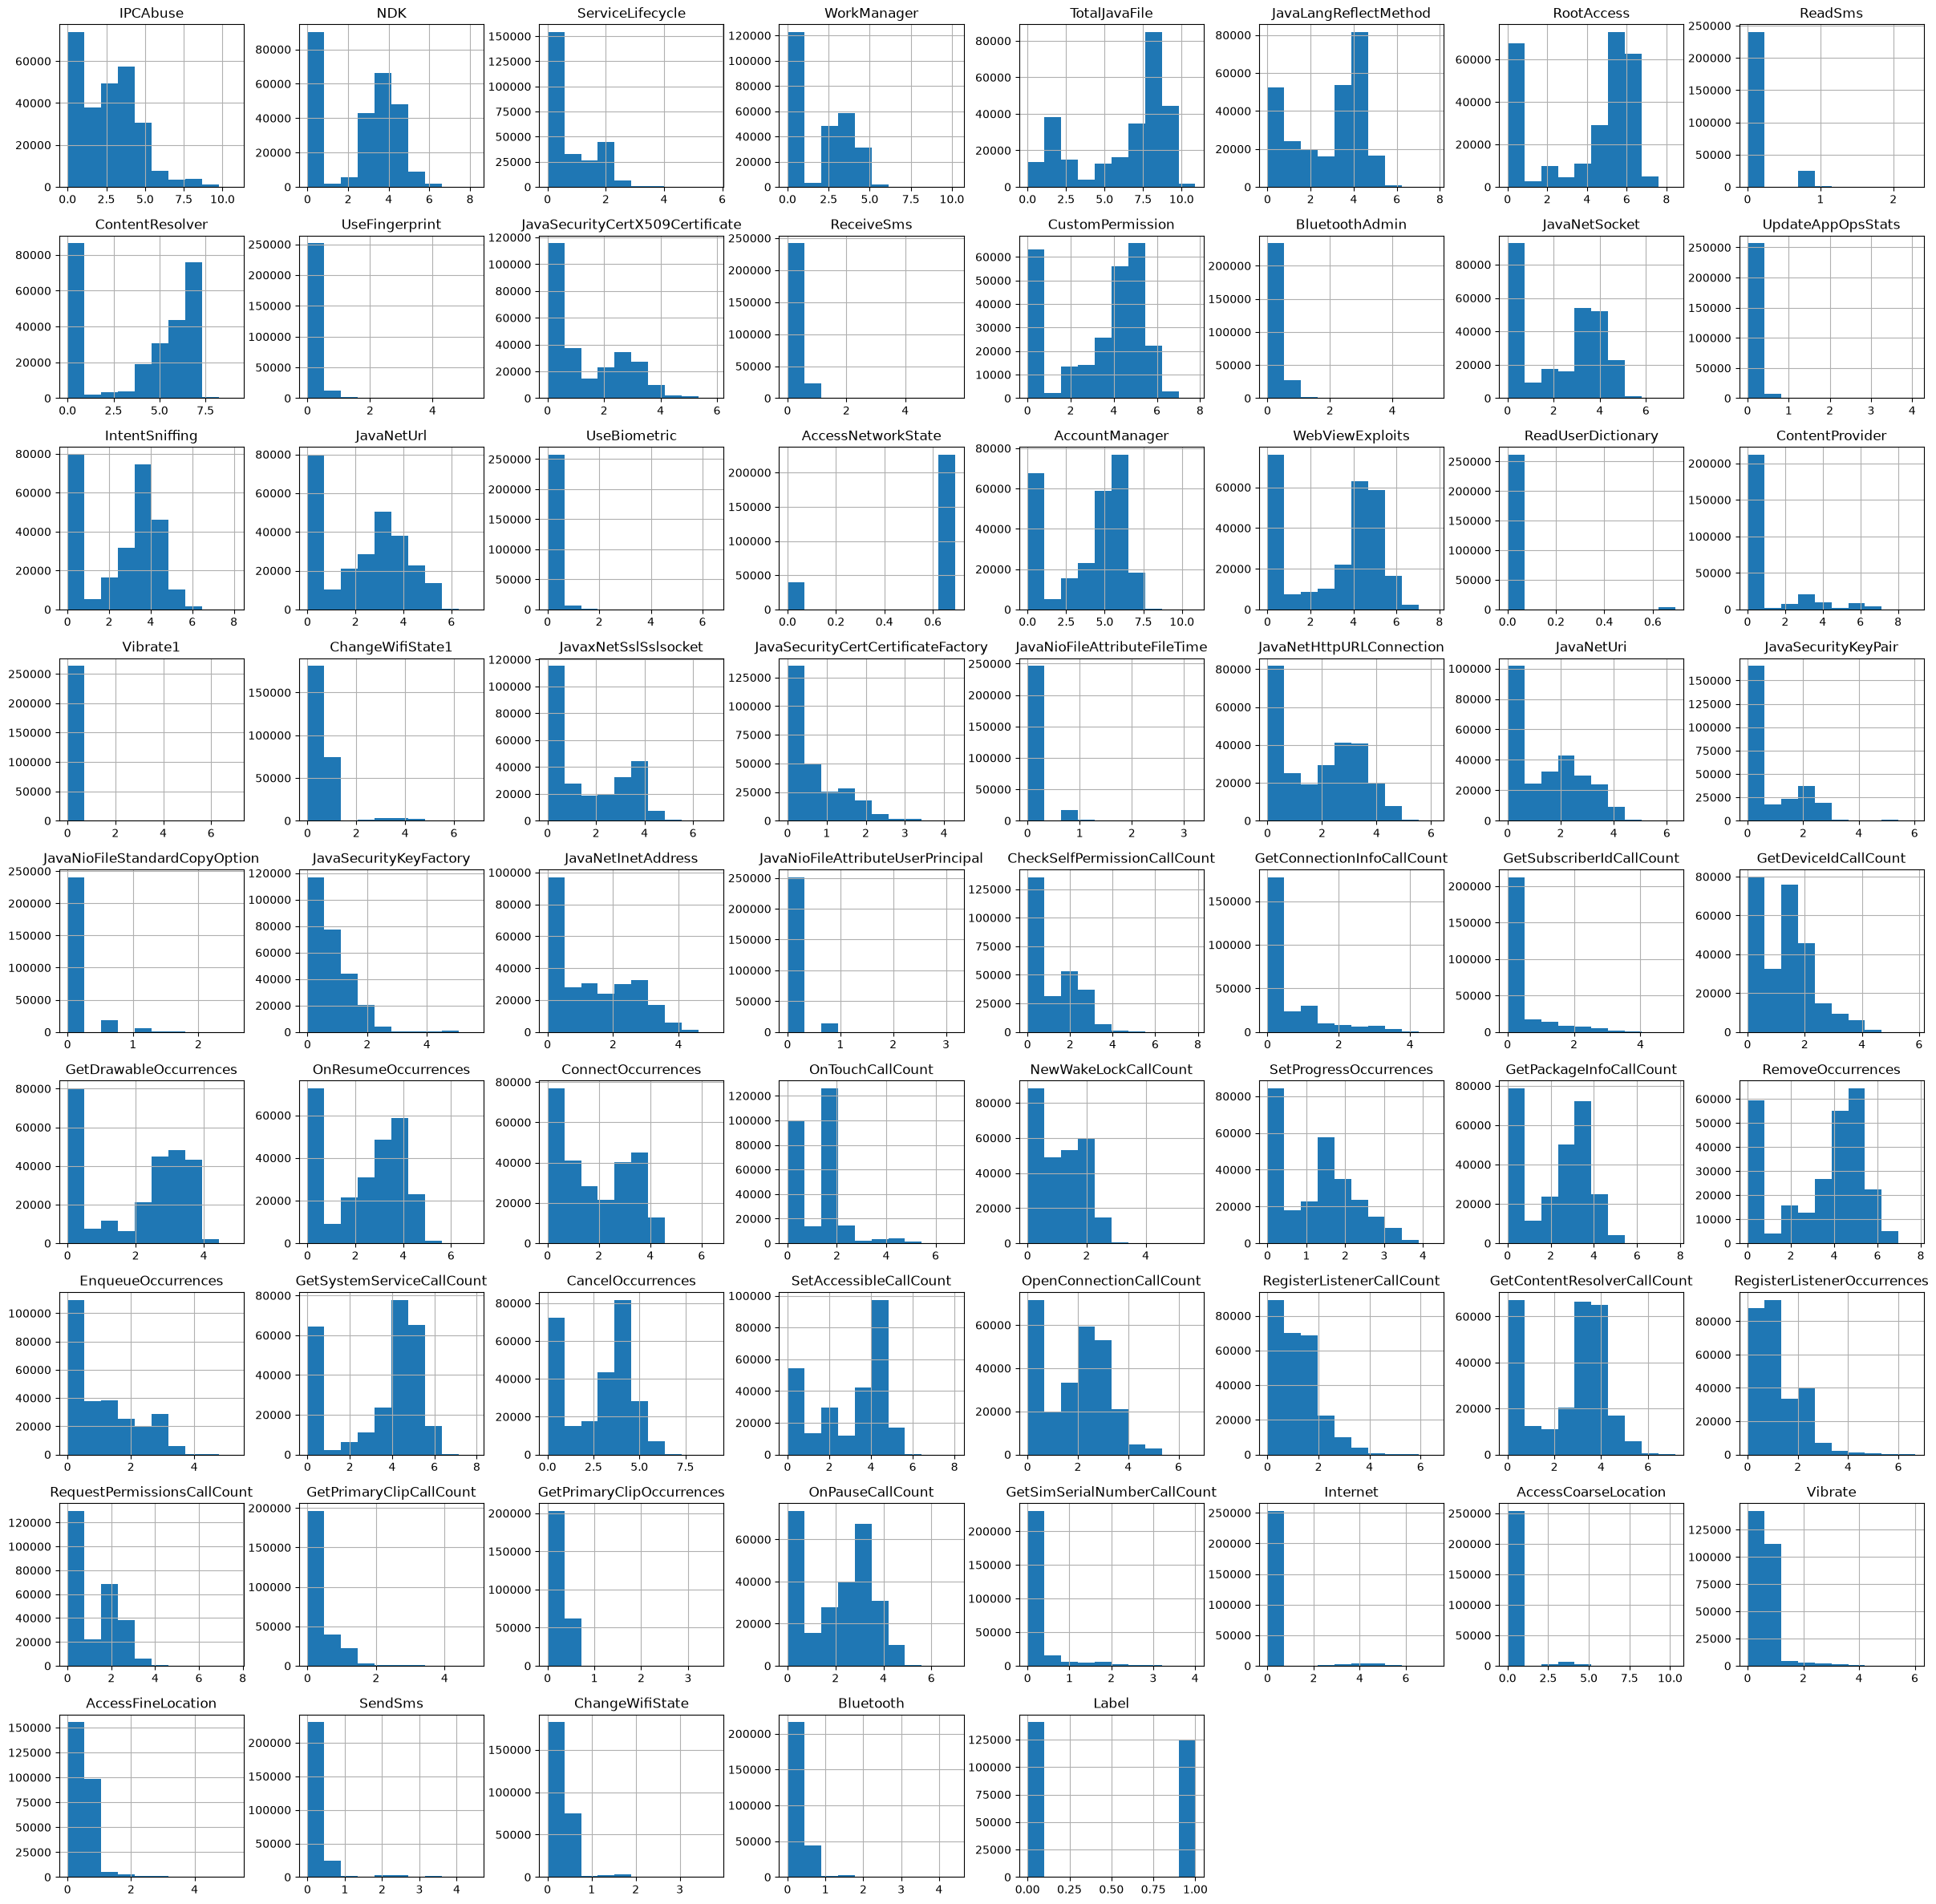

In [72]:
df.hist(figsize=(30, 30))

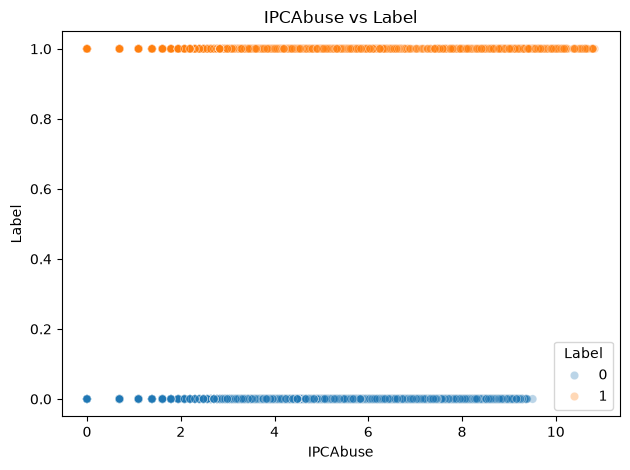

In [73]:
feature = "IPCAbuse"  # Choose your feature
target = "Label"         # Use "label" if your column name is lowercase

sns.scatterplot(
    data=df,
    x=feature,
    y=target,
    hue=target,
    alpha=0.3
)

plt.title(f"{feature} vs {target}")
plt.tight_layout()
plt.show()

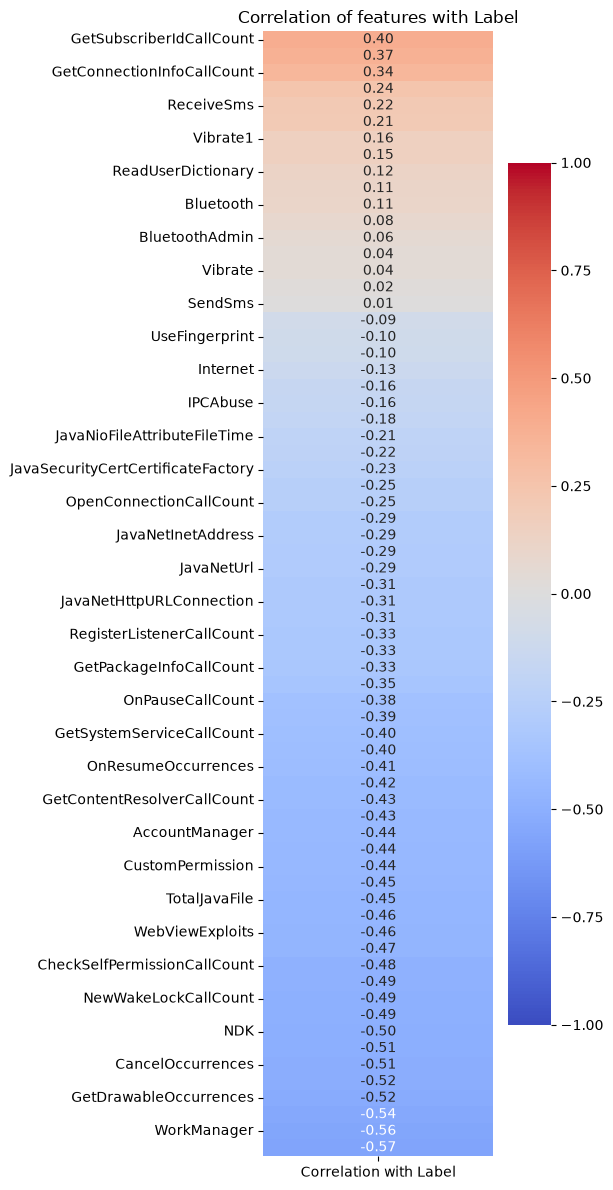

In [74]:
corr = df.corr(numeric_only=True)["Label"].drop("Label")
corr = corr.sort_values(ascending=False)

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr.to_frame(name="Correlation with Label"),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation of features with Label")
plt.tight_layout()
plt.show()

In [75]:
df.shape

(265423, 70)

In [76]:
X = df.drop(columns=["Label", "Sha256"], errors="ignore")
y = df["Label"]

In [77]:
X.shape

(265423, 68)

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [79]:
X_train.shape

(212338, 68)

In [80]:
print("Taille de l'entraînement :", X_train.shape)
print("Taille du test :", X_test.shape)

print("\nProportions dans le dataset complet :")
print(y.value_counts())

print("\nProportions dans l'entraînement :")
print(y_train.value_counts())

print("\nProportions dans le test :")
print(y_test.value_counts())

Taille de l'entraînement : (212338, 68)
Taille du test : (53085, 68)

Proportions dans le dataset complet :
Label
0    140722
1    124701
Name: count, dtype: int64

Proportions dans l'entraînement :
Label
0    112577
1     99761
Name: count, dtype: int64

Proportions dans le test :
Label
0    28145
1    24940
Name: count, dtype: int64


In [81]:
def show_confusion_matrix(y_test, y_pred, model_name): 
    ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
    )

    plt.title(f"{model_name}- Confusion Matrix")
    plt.tight_layout()
    plt.show()

              precision    recall  f1-score   support

           0       0.91      0.95      0.93     28145
           1       0.94      0.89      0.91     24940

    accuracy                           0.92     53085
   macro avg       0.92      0.92      0.92     53085
weighted avg       0.92      0.92      0.92     53085



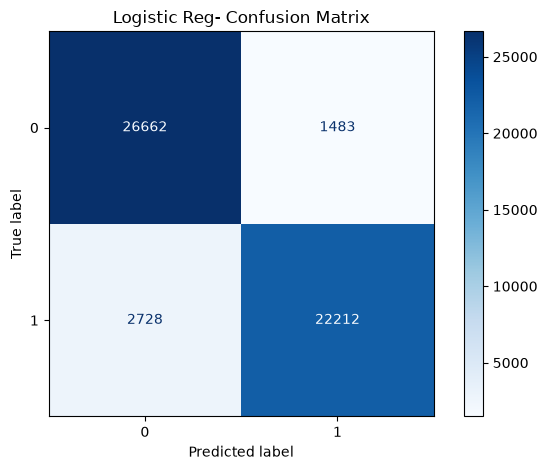

In [82]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

show_confusion_matrix(y_test, y_pred, "Logistic Reg")


              precision    recall  f1-score   support

           0       0.96      0.97      0.96     28145
           1       0.96      0.95      0.96     24940

    accuracy                           0.96     53085
   macro avg       0.96      0.96      0.96     53085
weighted avg       0.96      0.96      0.96     53085



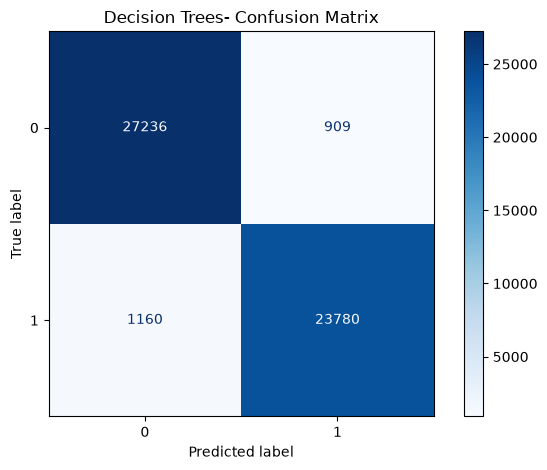

In [83]:
tree_model = DecisionTreeClassifier(
    max_depth=25,
    random_state=42
)

tree_model.fit(X_train, y_train)
y_pred = tree_model.predict(X_test)

print(classification_report(y_test, y_pred))

show_confusion_matrix(y_test, y_pred, "Decision Trees")


In [84]:
rules = export_text(
    tree_model,
    feature_names=X_train.columns.tolist()
)
print(rules)

|--- OnTouchCallCount <= 0.35
|   |--- RequestPermissionsCallCount <= 0.35
|   |   |--- GetPrimaryClipCallCount <= 0.90
|   |   |   |--- ServiceLifecycle <= 0.35
|   |   |   |   |--- OnPauseCallCount <= 0.35
|   |   |   |   |   |--- JavaSecurityCertX509Certificate <= 0.35
|   |   |   |   |   |   |--- AccessNetworkState <= 0.35
|   |   |   |   |   |   |   |--- SetAccessibleCallCount <= 0.35
|   |   |   |   |   |   |   |   |--- Internet <= 0.35
|   |   |   |   |   |   |   |   |   |--- IPCAbuse <= 2.25
|   |   |   |   |   |   |   |   |   |   |--- AccountManager <= 2.25
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 15
|   |   |   |   |   |   |   |   |   |   |--- AccountManager >  2.25
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |   |   |   |   |   |--- IPCAbuse >  2.25
|   |   |   |   |   |   |   |   |   |   |--- AccessCoarseLocation <= 2.44
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of dep

              precision    recall  f1-score   support

           0       0.97      0.98      0.98     28145
           1       0.98      0.97      0.98     24940

    accuracy                           0.98     53085
   macro avg       0.98      0.98      0.98     53085
weighted avg       0.98      0.98      0.98     53085



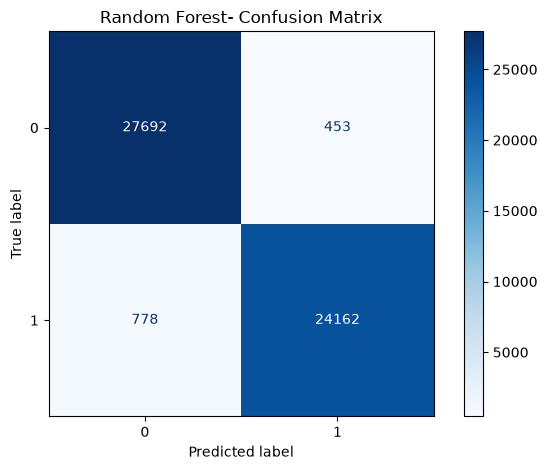

In [85]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print(classification_report(y_test, y_pred))

show_confusion_matrix(y_test, y_pred, "Random Forest")

In [86]:
dump(rf_model, "guardroid_model.joblib")

['guardroid_model.joblib']

In [87]:
model = load("guardroid_model.joblib")

In [110]:
rng = np.random.default_rng()
raw_vector = rng.integers(0, 11, size=68)
features = np.log1p(raw_vector).reshape(1, -1)
features = pd.DataFrame(features, columns=model.feature_names_in_)


In [111]:
start_time = time()
prediction = model.predict(features)[0]
end_time = time()

inf_time = end_time - start_time

print(f"Elapsed time: {inf_time:.4f} seconds")
print("Raw vector:", raw_vector.tolist())
print("Predicted class:", prediction)

Elapsed time: 0.1566 seconds
Raw vector: [10, 4, 2, 2, 9, 5, 5, 0, 9, 8, 3, 3, 6, 7, 0, 10, 6, 0, 3, 1, 7, 8, 4, 1, 3, 10, 0, 10, 4, 0, 5, 2, 4, 10, 2, 0, 3, 9, 2, 2, 3, 1, 4, 1, 7, 3, 8, 1, 7, 2, 2, 3, 5, 2, 0, 7, 9, 1, 9, 6, 2, 2, 5, 10, 5, 8, 1, 10]
Predicted class: 0
